# Classification with LoRA

**Vs classification:** same data, loss, training loop, and accuracy; train LoRA weights while existing weights stay frozen.

Complete the two LoRA cells in **§1**, then run top to bottom. The classification code is already filled in.

Compare with [02_classification.ipynb](02_classification.ipynb). LoRA follows [Appendix E updated](https://github.com/rasbt/LLMs-from-scratch/blob/main/appendix-E/01_main-chapter-code/appendix-E.ipynb).

## 0 · Goal & config

- **Mac:** local `.venv` kernel; run from `Training/`.
- **Runpod:** keep [setup.ipynb](../Runpod/setup.ipynb) on the local kernel and run **Start**. Here, choose **Select Kernel → Select Another Kernel → Existing Jupyter Server**, paste the URL, then choose **Python 3**. The first code cell sets the folder; device should print `cuda`.


In [1]:
from pathlib import Path

# Use the copied project folder on Runpod.
pod_folder = Path("/workspace/LLM-fine-tuning/Training")
if pod_folder.is_dir():
    %cd {pod_folder}

#### Imports

In [2]:
%load_ext autoreload
%autoreload 2

from datetime import datetime, timezone
import math

import pandas as pd
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from reference.configs import gpt2_BASE_CONFIG, gpt2_model_configs
from reference.data import load_spam_data, create_balanced_dataset, random_split, SpamDataset
from reference.evals import calc_accuracy_loader
from reference.generate import classify_review
from reference.losses import calc_loss_loader, calc_loss_batch_classification
from reference.model_io import download_weights, count_trainable_params
from reference.models.gpt2 import GPT2Model, load_weights_into_gpt
from reference.plot import plot_values
from reference.train import train_classifier_simple

#### Model config

In [3]:
# Options: gpt2-small (124M), gpt2-medium (355M), gpt2-large (774M), gpt2-xl (1558M).
CHOOSE_MODEL = "gpt2-small (124M)"

# ** unpacks dictionary entries; later values win on duplicate keys.
model_config = {**gpt2_BASE_CONFIG, **gpt2_model_configs[CHOOSE_MODEL]}

# Hugging Face calls the small model "gpt2".
model_repo = "openai-community/" + CHOOSE_MODEL.split()[0].replace("gpt2-small", "gpt2")

num_classes = 2
rank = 16
alpha = 16

#### Run folder

Save this experiment's checkpoints here.

In [4]:
folder = Path("runs/classification/002_lora")

#### Device

In [5]:
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print("device:", device)

device: mps


#### Tokenizer

In [6]:
tokenizer = tiktoken.get_encoding("gpt2")

## 1 · Load model

Start from the same pretrained GPT-2 and classification head as the baseline.

In [7]:
model = GPT2Model(model_config)
load_weights_into_gpt(model, download_weights(model_repo))

torch.manual_seed(123)
model.out_head = nn.Linear(model_config["emb_dim"], num_classes)
model = model.to(device)

/Users/faanjum/Developer/LLM-fine-tuning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 933.73it/s]


### LoRA layers

LoRALayer, LinearWithLoRA, and replace_linear_with_lora.

- A: torch.empty(...) reserves space; kaiming_uniform_ then fills it with random values.
- B: torch.zeros(...) fills it with zeros, so A @ B = 0 and initial predictions stay unchanged.
- Both zero: gradients would be zero, preventing learning.

In [8]:

class LoraLayer(nn.Module):
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.rank  = rank
        self.alpha = alpha
        self.A = nn.Parameter(torch.empty(in_dim, rank))
        nn.init.kaiming_uniform_(self.A, a = math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(rank, out_dim))

    def forward(self, x):
        return (self.alpha/self.rank) * (x @ self.A @ self.B)


class LinearwithLora(nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()    
        self.lora = LoraLayer(linear.in_features, linear.out_features, rank, alpha)
        self.linear = linear

    def forward(self, x):
        return self.linear(x) + self.lora(x)        


### Attach LoRA & create optimizer



In [9]:
print(count_trainable_params(model))
for params in model.parameters(): params.requires_grad = False
print(count_trainable_params(model))

124441346
0


In [10]:
def replace_linear_with_lora(model, rank, alpha):
    for name, module in model.named_children():
        if isinstance(module, nn.Linear):
            setattr(model, name, LinearwithLora(module, rank, alpha))
        else:
            replace_linear_with_lora(module, rank, alpha)

replace_linear_with_lora(model, rank = rank, alpha=alpha)
print(f"Model parameters after Lora: {count_trainable_params(model):,}")

Model parameters after Lora: 2,666,528


In [26]:
# TODO: freeze existing weights, add LoRA, and print the trainable parameter count.

model.to(device)
optimizer = torch.optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=8e-4, weight_decay=0.1,  # Appendix E settings.
)
print(model)

GPT2Model(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (attn): MaskedMultiHeadAttn(
        (W_query): LinearwithLora(
          (lora): LoraLayer()
          (linear): Linear(in_features=768, out_features=768, bias=True)
        )
        (W_key): LinearwithLora(
          (lora): LoraLayer()
          (linear): Linear(in_features=768, out_features=768, bias=True)
        )
        (W_value): LinearwithLora(
          (lora): LoraLayer()
          (linear): Linear(in_features=768, out_features=768, bias=True)
        )
        (out_proj): LinearwithLora(
          (lora): LoraLayer()
          (linear): Linear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): LinearwithLora(
            (lora): LoraLayer()
            (linear)

## 2 · Data + DataLoader

Load labeled text, prepare token IDs, and build batches.

| Input tokens | Training target |
|---|---|
| `[A, B, C]` | `1` (spam) |

One label for the whole message; the same target as classification.

In [12]:
df = load_spam_data()
df.head(3)

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...


### Balance & split data

In [13]:
balanced_df = create_balanced_dataset(df)
print(balanced_df['Label'].value_counts())

# Map Ham to 0, spam to 1
balanced_df['Label'] = balanced_df['Label'].map({"ham":0,"spam":1})
train_df, val_df, test_df = random_split(balanced_df, 0.7, 0.1)

Label
ham     747
spam    747
Name: count, dtype: int64


### Dataset

Return token IDs and a class label for each example.

In [14]:
train_dataset = SpamDataset(train_df, tokenizer, max_length = None)
val_dataset   = SpamDataset(val_df, tokenizer, max_length = train_dataset.max_length)
test_dataset  = SpamDataset(test_df, tokenizer, max_length = train_dataset.max_length)

### DataLoader

Build the loaders and inspect one batch.

In [15]:
num_workers = 0
batch_size  = 8

torch.manual_seed(123)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)
val_loader   = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)
test_loader  = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)

for input_batch, label_batch in train_loader:
    pass

print(f"input_batch: {input_batch.shape},Label shape: {label_batch.shape}")

input_batch: torch.Size([8, 120]),Label shape: torch.Size([8])


## 3 · Loss / objective

Same classification cross-entropy: class scores from the last token after padding.

In [16]:
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")


Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [17]:
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, loss_fn=calc_loss_batch_classification, num_batches=5)
    val_loss   = calc_loss_loader(val_loader, model, device, loss_fn=calc_loss_batch_classification, num_batches=5)
    test_loss  = calc_loss_loader(test_loader, model, device, loss_fn=calc_loss_batch_classification, num_batches=5)

print(f"Training Loss: {train_loss:.3f}")
print(f"Validation Loss: {val_loss:.3f}")
print(f"Test Loss: {test_loss:.3f}")

Training Loss: 2.453
Validation Loss: 2.583
Test Loss: 2.322


## 4 · Generate / predict

Predict class labels before training and record the starting accuracy.

In [18]:
txt = "You won million dollars"
classify_review(txt, model, tokenizer, device, max_length=train_dataset.max_length)

'spam'

## 5 · Train

Rerun training to continue with the current model and optimizer; `num_epochs` adds more epochs.

In [19]:
torch.manual_seed(123)
num_epochs = 5

train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, device, tokenizer, optimizer,
    train_loader, val_loader,
    eval_freq=50, eval_iter=5, epochs=num_epochs
)


epoch:1, step:000000: Train loss:3.651, Val loss:3.301
epoch:1, step:000050: Train loss:0.333, Val loss:0.331
epoch:1, step:000100: Train loss:0.152, Val loss:0.407
Training accuracy: 97.50% | Validation accuracy: 100.00%
epoch:2, step:000150: Train loss:0.160, Val loss:0.031
epoch:2, step:000200: Train loss:0.013, Val loss:0.043
epoch:2, step:000250: Train loss:0.066, Val loss:0.485
Training accuracy: 97.50% | Validation accuracy: 97.50%
epoch:3, step:000300: Train loss:0.024, Val loss:0.125
epoch:3, step:000350: Train loss:0.003, Val loss:0.183
Training accuracy: 100.00% | Validation accuracy: 92.50%
epoch:4, step:000400: Train loss:0.004, Val loss:0.157
epoch:4, step:000450: Train loss:0.030, Val loss:0.051
epoch:4, step:000500: Train loss:0.000, Val loss:0.119
Training accuracy: 100.00% | Validation accuracy: 92.50%
epoch:5, step:000550: Train loss:0.057, Val loss:0.275
epoch:5, step:000600: Train loss:0.019, Val loss:0.382
Training accuracy: 100.00% | Validation accuracy: 97.50%


### Plot Losses

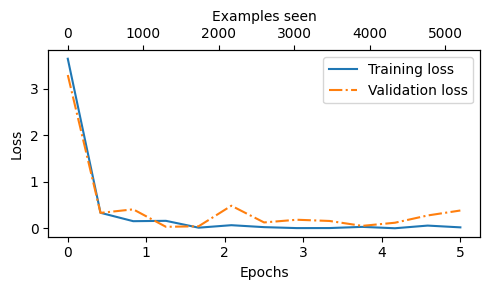

In [20]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

### Plot accuracy

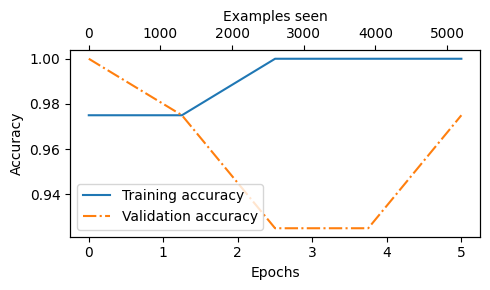

In [21]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))

plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")

In [22]:
examples = [
    ("Congratulations! You have won $1000 cash. Reply WIN to claim your prize now!", "spam"),
    ("URGENT! You have been selected for a FREE holiday. Call now to claim your exclusive reward!", "spam"),
    ("Hey, are we still meeting for dinner at seven tonight?", "not spam"),
    ("Please pick up some milk on your way home. Thanks!", "not spam"),
]


for text, expected in examples:
    predicted = classify_review(text, model, tokenizer, device, max_length=train_dataset.max_length)
    print(f"{text}\nExpected: {expected} | Predicted: {predicted}\n")

Congratulations! You have won $1000 cash. Reply WIN to claim your prize now!
Expected: spam | Predicted: spam

URGENT! You have been selected for a FREE holiday. Call now to claim your exclusive reward!
Expected: spam | Predicted: spam

Hey, are we still meeting for dinner at seven tonight?
Expected: not spam | Predicted: not spam

Please pick up some milk on your way home. Thanks!
Expected: not spam | Predicted: not spam



## 6 · Save checkpoint & predictions

**Runpod → Mac:** download this run's files into the same run folder on your Mac before **Delete → Confirm** in setup (local kernel). Deleting the pod also deletes its files.

#### Save model & optimizer

In [23]:
folder.mkdir(parents=True, exist_ok=True)
latest = folder / f"checkpoint_{datetime.now(timezone.utc):%Y%m%d_%H%M%S_%f}.pth"
checkpoint = {
    "model": model.state_dict(),
    "optimizer": optimizer.state_dict(),
    "model_config": model_config,
    "max_length": train_dataset.max_length,
    "rank": rank,
    "alpha": alpha,
}
torch.save(checkpoint, latest)
print(latest)

runs/classification/002_lora/checkpoint_20261025_190546_728206.pth


#### Extract predictions & save

In [24]:
# TODO: save predictions in the same run folder, using the checkpoint timestamp.

## 7 · Evaluate & reflect

Compare accuracy with the starting model and the classification baseline on the same held-out examples. Also compare trainable parameter counts. No judge model is needed.

In [25]:
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 99.04%
Validation accuracy: 97.99%
Test accuracy: 95.67%
